In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

In [3]:
test_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/test_data.csv')
training_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/training_data.csv')

training_x = training_data.drop('ClosePrice', axis=1)
training_y = training_data.ClosePrice

test_x = test_data.drop('ClosePrice', axis=1)
test_y = test_data.ClosePrice

In [10]:
# creates decision tree regressor

decision_tree = DecisionTreeRegressor()
decision_tree.fit(training_x, training_y)
dt_test_pred = decision_tree.predict(test_x)

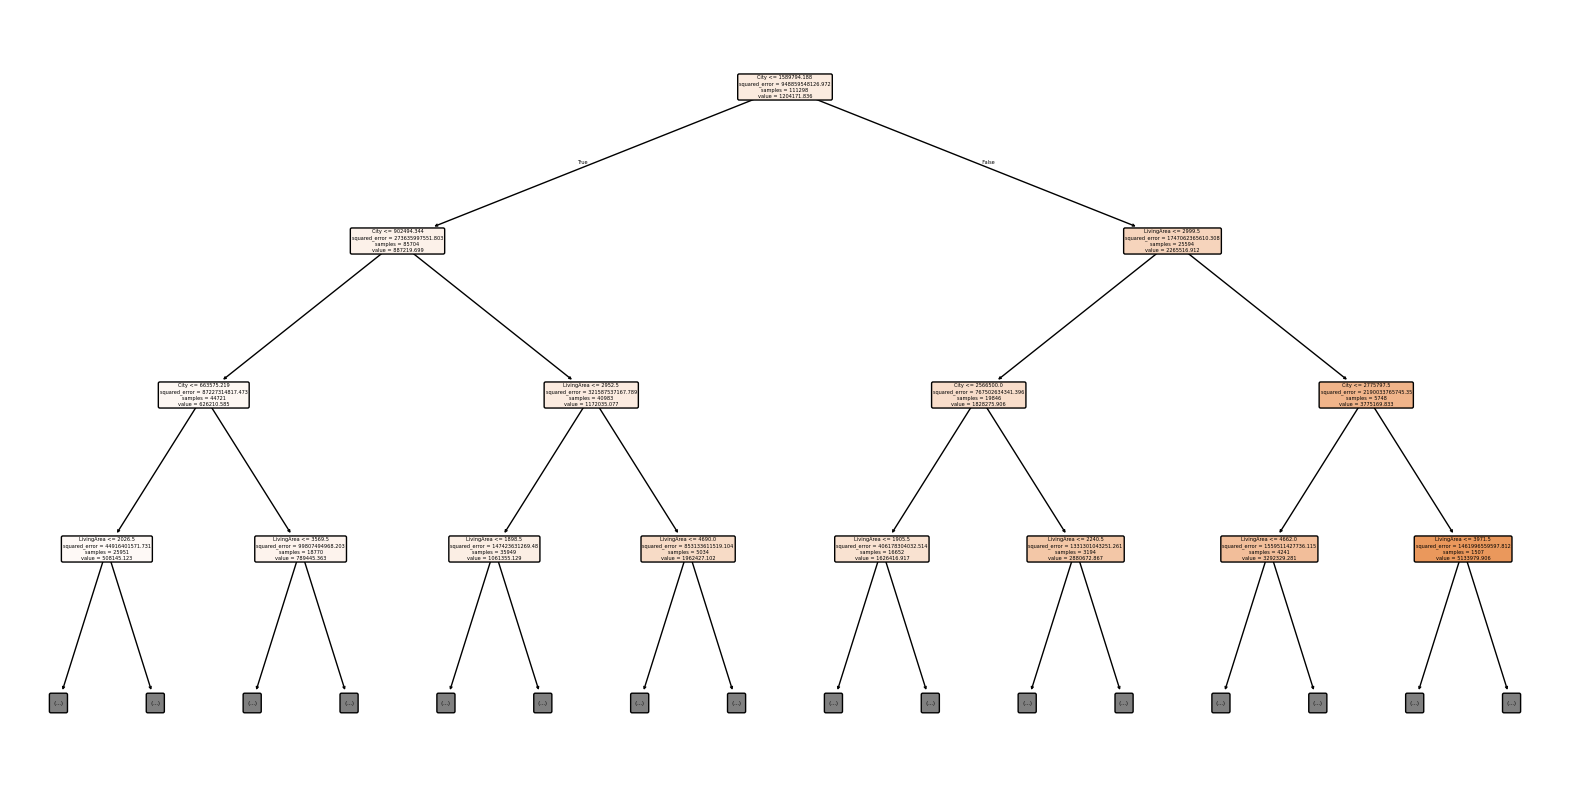

In [5]:
# visualize decision tree predictions

plt.figure(figsize=(20,10))
plot_tree(decision_tree, feature_names=training_x.columns, filled=True, rounded=True, max_depth=3)
plt.show()

In [11]:
# calculates R^2 for the decision tree model
decision_r2 = r2_score(test_y, dt_test_pred)
print(f"R^2: {decision_r2:.4f}")

R^2: 0.0092


In [16]:
# creates random forest mode 

random_forest = RandomForestRegressor()
random_forest.fit(training_x, training_y)
rf_test_pred = random_forest.predict(test_x)

In [20]:
# retrieves the importance of each attribute 
importance = pd.Series(random_forest.feature_importances_, index=training_x.columns)
importance.sort_values(ascending=False, inplace=True)
print(importance)

City                    0.557115
LivingArea              0.316032
LotSizeSquareFeet       0.035630
YearBuilt               0.034765
AssociationFeeYearly    0.016013
ParkingTotal            0.009874
BedroomsTotal           0.007561
MainLevelBedrooms       0.007231
Stories                 0.003697
AttachedGarageYN        0.002972
ViewYN                  0.002927
PoolPrivateYN           0.002359
FireplaceYN             0.002353
BasementYN              0.001136
NewConstructionYN       0.000336
dtype: float64


In [22]:
# calculates the R^2 score of our random forest model
rf_r2 = r2_score(test_y, rf_test_pred)
print(f"R^2: {rf_r2:.4f}")

R^2: 0.0106


In [ ]:
# both models perform better than the baseline linear regression model
# however, the increase in performance is not significant, only increasing by approximately .01 and .02
# the ranking of the models in terms of performance in ascending order is: linear regression, decision tree, random forest
# more complex models seem to perform better currently
# but we should note that all of them are not currently performing exceptionally well, so we will need to revisit this 
# more preprocessing might be necessary